# PROJECT TITLE: Exploratory Data Analysis of Smart Hospital Appointments

## Project Goals:
1. Analyze and clean the healthcare appointment dataset using Python.
2. Identify patterns in patient demographics, appointments, costs, and satisfaction using Pandas and NumPy.
3. Visualize important healthcare trends using Matplotlib, Seaborn, and Plotly.
4. Generate meaningful insights to understand appointment patterns and improve hospital services.

In [1]:
# Data manipulation and analysis
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Interactive visualizations
import plotly.express as px

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
df = pd.read_csv("/content/drive/MyDrive/Capstone Project/Smart_Hospital_Appointment_Dataset 1.csv")

## Dataset Information

| Attribute |	Value |
|---|---|
| Source | [Kaggle - Smart Hospital Appointments](https://www.kaggle.com/datasets/sonalshinde123/smart-healthcare-patient-appointment-dataset) |
| Records |	2716 patients |
| Features |	18 columns |


## Dataset Columns
- Patient Details: patient_id, age, gender, city, bmi, chronic_diseases
- Appointment Details: appointment_type, department, symptoms, severity_level, appointment_month, appointment_status
- Doctor Information: doctor_Experience_years, consultation_fee
- Insurance Details: insurance
- Medical Expenses: medicinal_cost, test_cost, total_bill
- Patient Feedback: patient_satisfaction_score

## Features List

- Data loading and cleaning (handling missing values, duplicates, and inconsistent values)
- Data type conversion and preprocessing
- Outlier detection and treatment using the IQR method
- Exploratory data analysis (EDA) using summary statistics
- Patient demographic analysis
- Appointment-wise and department-wise analysis
- Doctor experience and consultation fee analysis
- Medical cost and total bill analysis
- Patient satisfaction analysis
- Statistical analysis of numerical variables
- Data visualization using charts and graphs
- Comparison of appointment trends across departments, cities, and months
- Analysis of relationships between doctor experience, medical expenses, and patient satisfaction
- Identification of key insights and findings from the analysis

In [4]:
df

,Patient_id,age,Gender,city,BMI,chronic_disease,appointment_type,department,symptoms,severity_level,doctor_Experience_years,consultation_fee,insurance,appointment_month,appointment_status,patient_satisfaction_score,medicine_cost,test_cost
0,PAT_10000,52,Male,Mumbai,19.6,Hypertension,Scheduled,Neurology,Headache,Low,19.0,654,No,February,Completed,8.6,869,413
1,PAT_10001,21,Female,Mumbai,25.3,NaN,Scheduled,Neurology,Headache,Low,1.0,277,Yes,November,No Show,8.8,786,875
2,PAT_10002,51,Female,Bangalore,21.9,NaN,Scheduled,Dermatology,Skin Allergy,Low,18.0,691,Yes,June,No Show,10.0,466,427
3,PAT_10003,78,Female,Delhi,31.7,NaN,walk-in,Orthopedics,Joint Pain,Low,17.0,703,Yes,October,Completed,8.1,921,401
4,PAT_10004,62,Female,Mumbai,24.7,Hypertension,Scheduled,Ophthalmology,Eye Irritation,Low,15.0,699,Yes,May,Completed,8.9,152,216
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2711,PAT_12707,28,Male,Chennai,21.9,NaN,Walk-in,Cardiology,Chest Pain,High,2.0,304,No,November,Completed,10.0,11053,10314
2712,PAT_12708,37,Male,Ahmedabad,33.3,Diabetes,Scheduled,Gastroenterology,Stomach Pain,Low,8.0,402,Yes,August,No Show,10.0,590,253
2713,PAT_12709,67,Male,Hyderabad,19.9,Hypertension,Scheduled,General Medicine,Fever,Low,13.0,559,Yes,February,Completed,10.0,558,740
2714,PAT_12710,84,Male,Chennai,20.4,NaN,Scheduled,Pulmonology,Cough,Medium,28.0,916,No,February,Completed,10.0,3327,2693


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2716 entries, 0 to 2715
Data columns (total 18 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Patient_id                  2716 non-null   object 
 1   age                         2716 non-null   int64  
 2   Gender                      2716 non-null   object 
 3   city                        2696 non-null   object 
 4   BMI                         2716 non-null   float64
 5   chronic_disease             1480 non-null   object 
 6   appointment_type            2713 non-null   object 
 7   department                  2716 non-null   object 
 8   symptoms                    2710 non-null   object 
 9   severity_level              2716 non-null   object 
 10  doctor_Experience_years     2706 non-null   float64
 11  consultation_fee            2716 non-null   int64  
 12  insurance                   2716 non-null   object 
 13  appointment_month           2716 

In [6]:
df.head()

,Patient_id,age,Gender,city,BMI,chronic_disease,appointment_type,department,symptoms,severity_level,doctor_Experience_years,consultation_fee,insurance,appointment_month,appointment_status,patient_satisfaction_score,medicine_cost,test_cost
0,PAT_10000,52,Male,Mumbai,19.6,Hypertension,Scheduled,Neurology,Headache,Low,19.0,654,No,February,Completed,8.6,869,413
1,PAT_10001,21,Female,Mumbai,25.3,NaN,Scheduled,Neurology,Headache,Low,1.0,277,Yes,November,No Show,8.8,786,875
2,PAT_10002,51,Female,Bangalore,21.9,NaN,Scheduled,Dermatology,Skin Allergy,Low,18.0,691,Yes,June,No Show,10.0,466,427
3,PAT_10003,78,Female,Delhi,31.7,NaN,walk-in,Orthopedics,Joint Pain,Low,17.0,703,Yes,October,Completed,8.1,921,401
4,PAT_10004,62,Female,Mumbai,24.7,Hypertension,Scheduled,Ophthalmology,Eye Irritation,Low,15.0,699,Yes,May,Completed,8.9,152,216


In [7]:
df.tail()

,Patient_id,age,Gender,city,BMI,chronic_disease,appointment_type,department,symptoms,severity_level,doctor_Experience_years,consultation_fee,insurance,appointment_month,appointment_status,patient_satisfaction_score,medicine_cost,test_cost
2711,PAT_12707,28,Male,Chennai,21.9,NaN,Walk-in,Cardiology,Chest Pain,High,2.0,304,No,November,Completed,10.0,11053,10314
2712,PAT_12708,37,Male,Ahmedabad,33.3,Diabetes,Scheduled,Gastroenterology,Stomach Pain,Low,8.0,402,Yes,August,No Show,10.0,590,253
2713,PAT_12709,67,Male,Hyderabad,19.9,Hypertension,Scheduled,General Medicine,Fever,Low,13.0,559,Yes,February,Completed,10.0,558,740
2714,PAT_12710,84,Male,Chennai,20.4,NaN,Scheduled,Pulmonology,Cough,Medium,28.0,916,No,February,Completed,10.0,3327,2693
2715,PAT_12711,44,Male,Mumbai,22.3,Diabetes,Walk-in,Gynecology,Pregnancy Checkup,Medium,21.0,705,Yes,January,Completed,9.2,1954,1353


In [8]:
df.shape

(2716, 18)

In [9]:
df.columns

Index(['Patient_id', 'age', 'Gender', 'city', 'BMI', 'chronic_disease',
       'appointment_type', 'department', 'symptoms', 'severity_level',
       'doctor_Experience_years', 'consultation_fee', 'insurance',
       'appointment_month', 'appointment_status', 'patient_satisfaction_score',
       'medicine_cost', 'test_cost'],
      dtype='object')

In [10]:
df.dtypes

,0
Patient_id,object
age,int64
Gender,object
city,object
BMI,float64
chronic_disease,object
appointment_type,object
department,object
symptoms,object
severity_level,object


In [11]:
df.describe()

,age,BMI,doctor_Experience_years,consultation_fee,patient_satisfaction_score,medicine_cost,test_cost
count,2716.000000,2716.000000,2706.000000,2716.000000,2706.000000,2716.000000,2716.000000
mean,45.011046,24.079750,15.563562,610.861193,9.700074,4977.079161,3855.752209
std,26.070973,3.934693,8.806265,217.123073,0.538561,5591.871602,4109.890743
min,1.000000,15.000000,1.000000,220.000000,7.600000,100.000000,3.000000
25%,22.000000,21.400000,8.000000,460.000000,9.600000,730.000000,709.000000
50%,45.000000,23.900000,15.000000,611.000000,10.000000,2815.000000,2283.500000
75%,67.000000,26.800000,23.000000,757.000000,10.000000,7060.750000,5552.750000
max,201.000000,39.800000,90.000000,5000.000000,10.000000,19984.000000,14991.000000


In [12]:
df.isnull().sum()

,0
Patient_id,0
age,0
Gender,0
city,20
BMI,0
chronic_disease,1236
appointment_type,3
department,0
symptoms,6
severity_level,0


In [13]:
df.duplicated().sum()

np.int64(4)

## DATA CLEANING

*   Check the dataset: Understand the rows, columns, data types, and overall structure.
*   Handle missing values: Identify missing or blank data and treat them appropriately.
*   Remove duplicates: Find and remove repeated records.
Correct data types: Ensure each column has the appropriate data type.
*   Handle inconsistent values: Standardize different formats, spellings, and categories.
*   Detect outliers: Identify unusual or extreme values and handle them when necessary.
*   Validate the cleaned data: Recheck the dataset to ensure it is accurate, consistent, and ready for analysis


In [14]:
# Clean and Standardize column names
df.columns = df.columns.str.strip().str.lower().str.replace(' ', '_')

# Renaming the columns
df = df.rename(columns={
    "patient_satisfaction_score": "satisfaction_score",
    "test_cost": "lab_test_cost"
})

# Adding a new column total_bill
df['total_bill'] = df['consultation_fee'] + df['lab_test_cost'] + df['medicine_cost']

# Rechecking the column names
print(df.columns)

Index(['patient_id', 'age', 'gender', 'city', 'bmi', 'chronic_disease',
       'appointment_type', 'department', 'symptoms', 'severity_level',
       'doctor_experience_years', 'consultation_fee', 'insurance',
       'appointment_month', 'appointment_status', 'satisfaction_score',
       'medicine_cost', 'lab_test_cost', 'total_bill'],
      dtype='object')


#### 1. Missing Values: Check and handle missing data in doctor_experience_years, satisfaction_score, city, chronic_disease, appointment_type and symptoms.

In [15]:
# Fill numerical missing values using median
df['doctor_experience_years'] = df['doctor_experience_years'].fillna(
    df['doctor_experience_years'].median()
)

df['satisfaction_score'] = df['satisfaction_score'].fillna(
    df['satisfaction_score'].median()
)

# For categorical missing values

# 1. Fill missing values using mode
df['city'] = df['city'].fillna(df['city'].mode()[0])

# 2. Fill missing values with "Unknown"
df['chronic_disease'] = df['chronic_disease'].fillna('Unknown')
df['appointment_type'] = df['appointment_type'].fillna('Unknown')
df['symptoms'] = df['symptoms'].fillna('Unknown')

# Recheck for any missing values
print(df.isnull().sum())

patient_id                 0
age                        0
gender                     0
city                       0
bmi                        0
chronic_disease            0
appointment_type           0
department                 0
symptoms                   0
severity_level             0
doctor_experience_years    0
consultation_fee           0
insurance                  0
appointment_month          0
appointment_status         0
satisfaction_score         0
medicine_cost              0
lab_test_cost              0
total_bill                 0
dtype: int64


#### 2. Duplicate Values: Identify and remove duplicate records from the entire dataset.

In [16]:
df.duplicated().sum()


np.int64(4)

In [17]:
df = df.drop_duplicates()
df.duplicated().sum()

np.int64(0)

#### 3. Incorrect Data Types: Correct data types for patient_id,  consultation_fee, medicine_cost, lab_test_cost, total_bill, doctor_experience_years.

In [18]:
# Change data types
df['patient_id'] = df['patient_id'].astype(str)

df['consultation_fee'] = df['consultation_fee'].astype(float)

df['medicine_cost'] = df['medicine_cost'].astype(float)

df['lab_test_cost'] = df['lab_test_cost'].astype(float)

df['total_bill'] = df['total_bill'].astype(float)

df['doctor_experience_years'] = df['doctor_experience_years'].astype(int)

# Recheck for any incorrect data types
df.dtypes

,0
patient_id,object
age,int64
gender,object
city,object
bmi,float64
chronic_disease,object
appointment_type,object
department,object
symptoms,object
severity_level,object


#### 4. Inconsistent Values: Standardize values in gender, appointment_type, severity_level, and insurance by correcting capitalization and formatting.

In [19]:
# Standaridizing values in gender, appointment_type, severity_level, and insurance column to plain text

df['gender'] = df['gender'].str.strip().str.capitalize()
print(df['gender'].unique())

df['appointment_type'] = df['appointment_type'].str.strip().str.capitalize()
print(df['appointment_type'].unique())

df['severity_level'] = df['severity_level'].str.strip().str.capitalize()
print(df['severity_level'].unique())

df['insurance'] = df['insurance'].str.strip().str.capitalize()
print(df['insurance'].unique())

['Male' 'Female']
['Scheduled' 'Walk-in' 'Emergency' 'Unknown']
['Low' 'High' 'Medium']
['No' 'Yes']


#### 5. Outliers: Detect and handle unusual values in numerical columns.

In [20]:
# Checking for outliers
df.describe()

,age,bmi,doctor_experience_years,consultation_fee,satisfaction_score,medicine_cost,lab_test_cost,total_bill
count,2712.000000,2712.000000,2712.000000,2712.000000,2712.000000,2712.000000,2712.000000,2712.000000
mean,44.981195,24.084587,15.567478,611.075590,9.701180,4982.370206,3859.811947,9453.257743
std,26.073358,3.932994,8.794126,217.180173,0.538149,5593.983536,4111.102613,9212.891935
min,1.000000,15.000000,1.000000,220.000000,7.600000,100.000000,3.000000,474.000000
25%,22.000000,21.400000,8.000000,460.000000,9.600000,730.000000,711.500000,1923.750000
50%,45.000000,23.900000,15.000000,611.000000,10.000000,2823.000000,2285.500000,5816.500000
75%,67.000000,26.800000,23.000000,757.000000,10.000000,7086.250000,5562.750000,16984.000000
max,201.000000,39.800000,90.000000,5000.000000,10.000000,19984.000000,14991.000000,34669.000000


### **Outlier Handling**

1. Outliers are unusually high or low values that differ significantly from the majority of the data.
2. Detected outliers in age, doctor_experience_years, consultation_fee, and total_bill columns.
3. The **IQR (Interquartile Range) method** is used to identify outliers.
4. **Q1:** 25th percentile of the data.
5. **Q3:** 75th percentile of the data.
6. **IQR:** `Q3 − Q1`
7. **Lower Bound:** `Q1 − 1.5 × IQR`
8. **Upper Bound:** `Q3 + 1.5 × IQR`
9. Values below the lower bound or above the upper bound are considered 'outliers'.
10. The entire row containing an outlier will be removed, along with all the related values in that record.

In [21]:
# Detecting the outliers using IQR and displaying the count
outlier_cols = [
    'age',
    'doctor_experience_years',
    'consultation_fee'
]

for col in outlier_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    print("Column:", col)
    print("Q1:", Q1)
    print("Q3:", Q3)
    print("IQR:", IQR)
    print("Lower Bound:", lower_bound)
    print("Upper Bound:", upper_bound)
    print("Number of Outliers:", len(outliers))
    print("Outlier Values:", outliers[col].tolist())
    print("-" * 50)

Column: age
Q1: 22.0
Q3: 67.0
IQR: 45.0
Lower Bound: -45.5
Upper Bound: 134.5
Number of Outliers: 2
Outlier Values: [201, 201]
--------------------------------------------------
Column: doctor_experience_years
Q1: 8.0
Q3: 23.0
IQR: 15.0
Lower Bound: -14.5
Upper Bound: 45.5
Number of Outliers: 2
Outlier Values: [90, 90]
--------------------------------------------------
Column: consultation_fee
Q1: 460.0
Q3: 757.0
IQR: 297.0
Lower Bound: 14.5
Upper Bound: 1202.5
Number of Outliers: 2
Outlier Values: [5000.0, 5000.0]
--------------------------------------------------


In [22]:
# Remove invalid Age values
df = df[(df['age'] >= 0) & (df['age'] <= 100)]

# Remove invalid Doctor Experience values
df = df[(df['doctor_experience_years'] >= 0) &
        (df['doctor_experience_years'] <= 60)]

# Remove Consultation Fee outliers
df = df[(df['consultation_fee'] >= 0) &
        (df['consultation_fee'] < 1000)]

# Recheck for outliers
print(df[outlier_cols].describe())

               age  doctor_experience_years  consultation_fee
count  2706.000000              2706.000000        2706.00000
mean     44.838137                15.519956         608.09867
std      25.738692                 8.565188         181.55439
min       1.000000                 1.000000         220.00000
25%      22.000000                 8.000000         460.00000
50%      45.000000                15.000000         611.00000
75%      67.000000                23.000000         757.00000
max      89.000000                30.000000         998.00000


In [23]:
df

,patient_id,age,gender,city,bmi,chronic_disease,appointment_type,department,symptoms,severity_level,doctor_experience_years,consultation_fee,insurance,appointment_month,appointment_status,satisfaction_score,medicine_cost,lab_test_cost,total_bill
0,PAT_10000,52,Male,Mumbai,19.6,Hypertension,Scheduled,Neurology,Headache,Low,19,654.0,No,February,Completed,8.6,869.0,413.0,1936.0
1,PAT_10001,21,Female,Mumbai,25.3,Unknown,Scheduled,Neurology,Headache,Low,1,277.0,Yes,November,No Show,8.8,786.0,875.0,1938.0
2,PAT_10002,51,Female,Bangalore,21.9,Unknown,Scheduled,Dermatology,Skin Allergy,Low,18,691.0,Yes,June,No Show,10.0,466.0,427.0,1584.0
3,PAT_10003,78,Female,Delhi,31.7,Unknown,Walk-in,Orthopedics,Joint Pain,Low,17,703.0,Yes,October,Completed,8.1,921.0,401.0,2025.0
4,PAT_10004,62,Female,Mumbai,24.7,Hypertension,Scheduled,Ophthalmology,Eye Irritation,Low,15,699.0,Yes,May,Completed,8.9,152.0,216.0,1067.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2711,PAT_12707,28,Male,Chennai,21.9,Unknown,Walk-in,Cardiology,Chest Pain,High,2,304.0,No,November,Completed,10.0,11053.0,10314.0,21671.0
2712,PAT_12708,37,Male,Ahmedabad,33.3,Diabetes,Scheduled,Gastroenterology,Stomach Pain,Low,8,402.0,Yes,August,No Show,10.0,590.0,253.0,1245.0
2713,PAT_12709,67,Male,Hyderabad,19.9,Hypertension,Scheduled,General Medicine,Fever,Low,13,559.0,Yes,February,Completed,10.0,558.0,740.0,1857.0
2714,PAT_12710,84,Male,Chennai,20.4,Unknown,Scheduled,Pulmonology,Cough,Medium,28,916.0,No,February,Completed,10.0,3327.0,2693.0,6936.0


In [24]:
df.shape

(2706, 19)

## Exploratory Data Analysis (EDA)

Exploratory Data Analysis (EDA) is used to understand the hospital appointment dataset, identify patterns and trends, detect outliers, and explore relationships between patient details, appointments, medical expenses, and patient satisfaction to obtain meaningful insights.

### Understanding individual columns
*   Check for the data types, number of records, and missing values.


In [25]:
# Check column names and data types
df.info()

# Check missing values
df.isnull().sum()


<class 'pandas.core.frame.DataFrame'>
Index: 2706 entries, 0 to 2715
Data columns (total 19 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   patient_id               2706 non-null   object 
 1   age                      2706 non-null   int64  
 2   gender                   2706 non-null   object 
 3   city                     2706 non-null   object 
 4   bmi                      2706 non-null   float64
 5   chronic_disease          2706 non-null   object 
 6   appointment_type         2706 non-null   object 
 7   department               2706 non-null   object 
 8   symptoms                 2706 non-null   object 
 9   severity_level           2706 non-null   object 
 10  doctor_experience_years  2706 non-null   int64  
 11  consultation_fee         2706 non-null   float64
 12  insurance                2706 non-null   object 
 13  appointment_month        2706 non-null   object 
 14  appointment_status       2706

,0
patient_id,0
age,0
gender,0
city,0
bmi,0
chronic_disease,0
appointment_type,0
department,0
symptoms,0
severity_level,0


### Analyze numerical data
*   To Understand numerical columns such as age, BMI, doctor experience,
consultation fee, medicinal cost, test cost, total bill, and patient satisfaction score.
*   Calculated the mean, median, minimum, maximum, and standard deviation to understand the data.

In [26]:
numerical_columns = [
    'age', 'bmi', 'doctor_experience_years',
    'consultation_fee', 'medicine_cost',
    'lab_test_cost', 'total_bill',
    'satisfaction_score'
]

print("Mean:")
print(df[numerical_columns].mean())

print("\nMedian:")
print(df[numerical_columns].median())

print("\nMinimum:")
print(df[numerical_columns].min())

print("\nMaximum:")
print(df[numerical_columns].max())

print("\nStandard Deviation:")
print(df[numerical_columns].std())


Mean:
age                          44.838137
bmi                          24.088322
doctor_experience_years      15.519956
consultation_fee            608.098670
medicine_cost              4989.132668
lab_test_cost              3864.716556
total_bill                 9461.947894
satisfaction_score            9.701922
dtype: float64

Median:
age                          45.0
bmi                          23.9
doctor_experience_years      15.0
consultation_fee            611.0
medicine_cost              2826.5
lab_test_cost              2290.0
total_bill                 5818.5
satisfaction_score           10.0
dtype: float64

Minimum:
age                          1.0
bmi                         15.0
doctor_experience_years      1.0
consultation_fee           220.0
medicine_cost              100.0
lab_test_cost                3.0
total_bill                 474.0
satisfaction_score           7.6
dtype: float64

Maximum:
age                           89.0
bmi                           39.8
do

### Groupby and average analysis
*   Comparing average values across different groups.
*   Calculating the average total bill for each department, average consultation fee for different doctor experience levels, and average satisfaction score by department.   




#### 1. Average total bill by department

In [27]:
print("Average Total Bill by Department:")
print(df.groupby('department')['total_bill'].mean())

Average Total Bill by Department:
department
Cardiology          14646.057878
Dental              10543.559259
Dermatology         10188.736220
Gastroenterology    10206.583630
General Medicine     5684.125490
Gynecology          14144.973684
Neurology            5074.507937
Ophthalmology        9042.507042
Orthopedics          9394.268722
Pulmonology          5081.683007
Name: total_bill, dtype: float64


#### 2. Average consultation fee by doctor experience

In [28]:
print("Average Consultation Fee by Doctor Experience:")
print(df.groupby('doctor_experience_years')['consultation_fee'].mean())

Average Consultation Fee by Doctor Experience:
doctor_experience_years
1     318.291139
2     334.515464
3     361.313253
4     379.382716
5     396.419753
6     418.123711
7     433.409091
8     469.010101
9     472.532609
10    506.152174
11    510.565217
12    542.888889
13    561.510417
14    586.012987
15    573.341880
16    621.891304
17    641.623529
18    654.670588
19    679.222222
20    698.295238
21    710.743590
22    741.990654
23    773.157143
24    780.168539
25    792.703297
26    812.228916
27    838.395349
28    864.608696
29    864.977528
30    900.851064
Name: consultation_fee, dtype: float64


#### 3. Average satisfaction score by department

In [29]:
print("Average Satisfaction by Department:")
print(df.groupby('department')['satisfaction_score'].mean())

Average Satisfaction by Department:
department
Cardiology          9.892926
Dental              9.661852
Dermatology         9.722441
Gastroenterology    9.703203
General Medicine    9.575294
Gynecology          9.886090
Neurology           9.560714
Ophthalmology       9.719718
Orthopedics         9.686344
Pulmonology         9.581699
Name: satisfaction_score, dtype: float64


### Analyze categorical data


*   To Understand the frequency of categories in columns such as
    gender, city, chronic disease,
    appointment type, department, symptoms,
    severity level, insurance,
    appointment month, appointment status.
*   Count the number of records belonging to each category.

In [30]:
categorical_cols = [
    'gender', 'city', 'chronic_disease',
    'appointment_type', 'department', 'symptoms',
    'severity_level', 'insurance',
    'appointment_month', 'appointment_status'
]

for col in categorical_cols:
    if col in df.columns:
        print("\nCategory Analysis:", col)
        print(df[col].value_counts(dropna=False))


Category Analysis: gender
gender
Male      1359
Female    1347
Name: count, dtype: int64

Category Analysis: city
city
Ahmedabad    327
Delhi        296
Jaipur       275
Pune         270
Hyderabad    268
Kolkata      261
Nagpur       257
Mumbai       251
Bangalore    251
Chennai      250
Name: count, dtype: int64

Category Analysis: chronic_disease
chronic_disease
Unknown          1234
Diabetes          536
Hypertension      528
Asthma            275
Heart Disease     133
Name: count, dtype: int64

Category Analysis: appointment_type
appointment_type
Scheduled    1472
Walk-in       851
Emergency     380
Unknown         3
Name: count, dtype: int64

Category Analysis: department
department
Cardiology          311
Pulmonology         306
Ophthalmology       284
Gastroenterology    281
Dental              270
Gynecology          266
General Medicine    255
Dermatology         254
Neurology           252
Orthopedics         227
Name: count, dtype: int64

Category Analysis: symptoms
symptom

### Most common categories
*   To find the most frequently occurring category in each column.
*   Identifying using mode() to recognize the most common value and value_counts() to show its frequency.

In [31]:
categorical_cols = [
    'gender', 'city', 'chronic_disease',
    'appointment_type', 'department', 'symptoms',
    'severity_level', 'insurance',
    'appointment_month', 'appointment_status'
]

for col in categorical_cols:
    if col in df.columns:
        print("\nMost Common Category:", col)
        print("Category:", df[col].mode().tolist())
        print("Frequency:")
        print(df[col].value_counts().head(5))


Most Common Category: gender
Category: ['Male']
Frequency:
gender
Male      1359
Female    1347
Name: count, dtype: int64

Most Common Category: city
Category: ['Ahmedabad']
Frequency:
city
Ahmedabad    327
Delhi        296
Jaipur       275
Pune         270
Hyderabad    268
Name: count, dtype: int64

Most Common Category: chronic_disease
Category: ['Unknown']
Frequency:
chronic_disease
Unknown          1234
Diabetes          536
Hypertension      528
Asthma            275
Heart Disease     133
Name: count, dtype: int64

Most Common Category: appointment_type
Category: ['Scheduled']
Frequency:
appointment_type
Scheduled    1472
Walk-in       851
Emergency     380
Unknown         3
Name: count, dtype: int64

Most Common Category: department
Category: ['Cardiology']
Frequency:
department
Cardiology          311
Pulmonology         306
Ophthalmology       284
Gastroenterology    281
Dental              270
Name: count, dtype: int64

Most Common Category: symptoms
Category: ['Chest Pain']


## Distribution Analysis – Statistical Details


*   Uses describe() to examine the range, average, and spread of numerical values.
*   The output includes minimum, maximum, and quartiles to help identify unusual values.

### Distribution Analysis – Key Findings
1. Age: The average patient age was 45 years, ranging from 1 to 89 years.
2. BMI: The average BMI was 24.09, which falls within the normal adult BMI range.
3. Doctor Experience: Doctors had an average experience of approximately 16 years.
4. Consultation Fee: The average consultation fee was ₹608.
5. Satisfaction Score: The average satisfaction score was high at 9.70 out of 10.
6. Medicine Cost: The average medicine cost was ₹4,989, with considerable variation across patients.
7. Lab Test Cost: The average lab test cost was ₹3,865.
8. Total Bill: The average total bill was ₹9,462, while the median was ₹5,819, indicating that higher bills may be pulling the average upward.



In [32]:
print(df.describe())

               age          bmi  doctor_experience_years  consultation_fee  \
count  2706.000000  2706.000000              2706.000000        2706.00000   
mean     44.838137    24.088322                15.519956         608.09867   
std      25.738692     3.932717                 8.565188         181.55439   
min       1.000000    15.000000                 1.000000         220.00000   
25%      22.000000    21.400000                 8.000000         460.00000   
50%      45.000000    23.900000                15.000000         611.00000   
75%      67.000000    26.800000                23.000000         757.00000   
max      89.000000    39.800000                30.000000         998.00000   

       satisfaction_score  medicine_cost  lab_test_cost    total_bill  
count         2706.000000    2706.000000    2706.000000   2706.000000  
mean             9.701922    4989.132668    3864.716556   9461.947894  
std              0.537816    5597.893921    4113.923960   9219.178015  
min      

## Percentage Analysis
- Calculates the percentage of records in each category.
- Helps compare gender, appointment type, insurance, and appointment status.

Formula: Percentage = (Category count / Total records) × 100

### Percentage Analysis – Key Findings
1. Gender: Male patients (50.22%) were slightly higher than female patients (49.78%).
2. Appointment Type: Scheduled appointments (54.4%) were the highest, followed by walk-in (31.45%) and emergency appointments (14.04%). Unknown appointments accounted for only 0.11%.
3. Insurance: Most patients had insurance (59.76%), while 40.24% did not have insurance.
4. Appointment Status: Most appointments were completed (82.74%), while 12.42% were no-shows and 4.84% were cancelled.

In [33]:
percentage_cols = [
    'gender', 'appointment_type',
    'insurance', 'appointment_status'
]

for col in percentage_cols:
    print(f"\nPercentage distribution of {col}:")
    print(((df[col].value_counts(normalize=True) * 100).round(2).astype(str) + ' %'))


Percentage distribution of gender:
gender
Male      50.22 %
Female    49.78 %
Name: proportion, dtype: object

Percentage distribution of appointment_type:
appointment_type
Scheduled     54.4 %
Walk-in      31.45 %
Emergency    14.04 %
Unknown       0.11 %
Name: proportion, dtype: object

Percentage distribution of insurance:
insurance
Yes    59.76 %
No     40.24 %
Name: proportion, dtype: object

Percentage distribution of appointment_status:
appointment_status
Completed    82.74 %
No Show      12.42 %
Cancelled     4.84 %
Name: proportion, dtype: object


## Correlation Analysis

*   Examines relationships between numerical columns.
*   Values range from −1 to +1, indicating the direction and strength of linear relationships.

### Correlation Analysis - Key Findings
1. Medicine cost and total bill showed the strongest positive relationship (correlation = +0.963).
2. Doctor experience and consultation fee showed a very strong positive relationship (correlation = +0.942).
3. Lab test cost and total bill showed a very strong positive relationship (correlation = +0.929).
4. Medicine cost and lab test cost showed a strong positive relationship (correlation = +0.795).
5. Satisfaction score and total bill showed a moderate positive relationship (correlation = +0.434).

In [34]:
# Select numerical columns
numeric_df = df.select_dtypes(include='number')

# Calculate correlation
correlation = numeric_df.corr()

# Display the result
print("Correlation Analysis:")
print(correlation.round(4))

Correlation Analysis:
                            age     bmi  doctor_experience_years  \
age                      1.0000  0.0273                   0.0110   
bmi                      0.0273  1.0000                   0.0322   
doctor_experience_years  0.0110  0.0322                   1.0000   
consultation_fee         0.0124  0.0298                   0.9418   
satisfaction_score      -0.0073 -0.0104                  -0.0088   
medicine_cost            0.0023  0.0084                   0.0201   
lab_test_cost           -0.0029  0.0300                   0.0065   
total_bill               0.0003  0.0191                   0.0336   

                         consultation_fee  satisfaction_score  medicine_cost  \
age                                0.0124             -0.0073         0.0023   
bmi                                0.0298             -0.0104         0.0084   
doctor_experience_years            0.9418             -0.0088         0.0201   
consultation_fee                   1.0000    

## DATA VISUALIZATION
 *It is the process of converting raw datasets into graphical representations (like charts, graphs, and maps) to easily uncover trends, patterns, and outliers.*

### 1. Bar Chart – Appointment Status
Bar Chart compares appointment status categories with the number of appointments.
*   Goal: To identify the most and least common statuses.
*   Categories used: appointment_status and the number of appointments in each category.


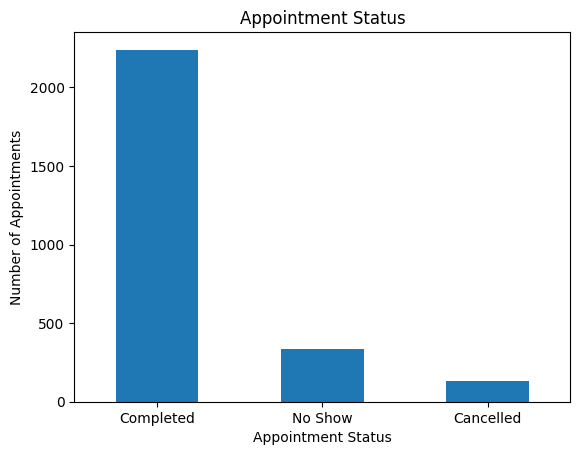

In [35]:
df['appointment_status'].value_counts().plot(kind='bar')
plt.title('Appointment Status')
plt.xlabel('Appointment Status')
plt.ylabel('Number of Appointments')
plt.xticks(rotation=0)
plt.show()

*   Output explanation: The bars represent the number of appointments in each status category, with taller bars indicating higher counts.
*   Insight: Completed appointments account for 82.74%, while no-shows account for 12.42% and cancellations account for 4.84%.

### 2. Line Chart – Monthly Appointment Trends

Line Chart shows monthly appointment trends by connecting the number of appointments recorded in each month.
*   Goal: To identify changes in appointment volumes over time.
*   Categories used: appointment_month and the number of appointments in each month.


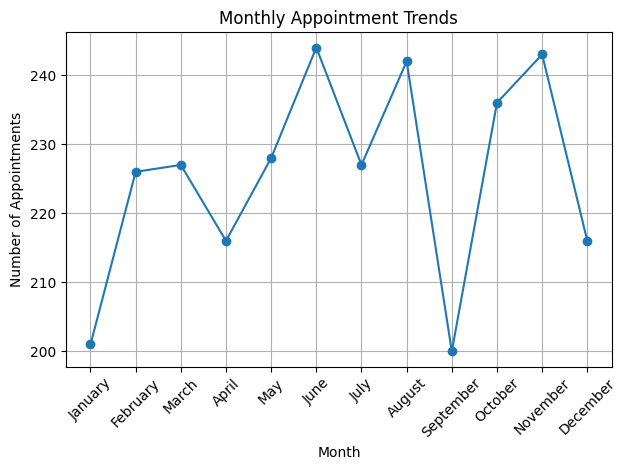

In [36]:
months = ['January', 'February', 'March', 'April',
          'May', 'June', 'July', 'August',
          'September', 'October', 'November', 'December']

monthly = df['appointment_month'].value_counts().reindex(months, fill_value=0)

monthly.plot(kind='line', marker='o')

plt.title('Monthly Appointment Trends')
plt.xlabel('Month')
plt.ylabel('Number of Appointments')
plt.xticks(range(12), months, rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

*   Output explanation: The line connects monthly appointment counts, showing increases and decreases in appointment volume.
*   Insight: The graph identifies the highest appointment counts in June slightly above November and lowest appointment counts in September.

### 3. Histogram – Patient Age Distribution
Histogram shows the distribution of patients across different age ranges.
*   Goal: To identify the age intervals containing the most and fewest patients.
*   Categories used: age, grouped into numerical intervals.

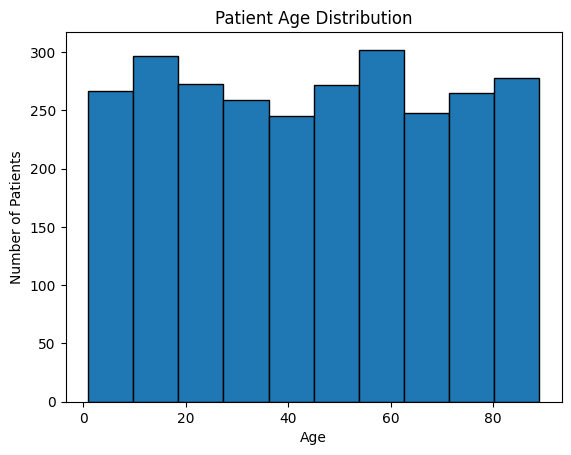

In [37]:
plt.hist(df['age'], bins=10, edgecolor='black')
plt.title('Patient Age Distribution')
plt.xlabel('Age')
plt.ylabel('Number of Patients')
plt.show()


*   Output explanation: Each bar represents an age interval, and its height indicates the number of patients within that interval.
*   Insight: The average patient age is 44.84 years, the median is 45 years, and ages range from 1 to 89 years.

### 4. Box Plot – Medicine Cost Outlier Analysis
Box Plot shows the spread, median, and potential outliers in the medicine cost.

*   Goal: To identify unusually high or low medicine expenses.
*   Category used: medicine_cost — the numerical cost of medicines for each patient.

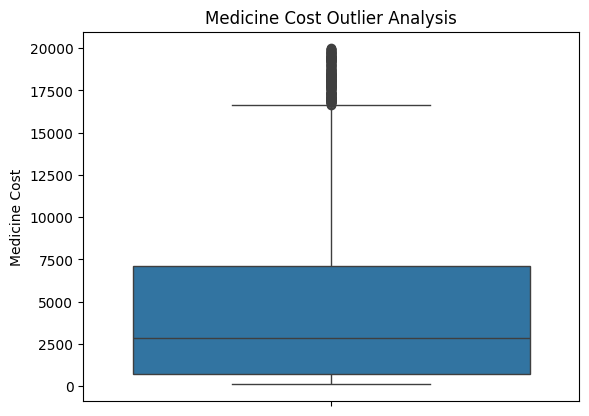

In [38]:
sns.boxplot(y=df['medicine_cost'])

plt.title('Medicine Cost Outlier Analysis')
plt.ylabel('Medicine Cost')
plt.show()



*   Output explanation: The box represents the middle 50% of medicine costs, the central line represents the median, and points beyond the whiskers indicate potential outliers.
*   Insight: Medicine costs range from ₹100 to ₹19,984, with ₹19,984 identified as the suspected high-cost outlier to check in the graph.

### 5. Scatter Plot – Medicine Cost vs. Total Bill

Scatter Plot shows the relationship between medicine cost and total bill.
*   Goal: To identify the direction and strength of the relationship between two numerical variables.
*   Categories used: medicine_cost on the x-axis and total_bill on the y-axis.

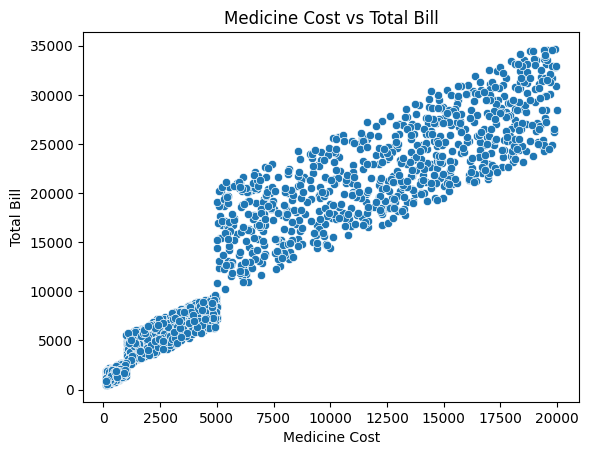

In [39]:
sns.scatterplot(
    data=df,
    x='medicine_cost',
    y='total_bill'
)

plt.title('Medicine Cost vs Total Bill')
plt.xlabel('Medicine Cost')
plt.ylabel('Total Bill')
plt.show()



*   Output explanation: Each point represents a patient record, and an upward pattern indicates that higher medicine costs tend to be associated with higher total bills.
*   Insight: Medicine cost and total bill have a very strong positive correlation of +0.963.

### 6. Pie Chart – Gender Distribution

Pie Chart shows the percentage distribution of male and female patients.

*   Goal: To compare the proportions of different gender categories.
*   Categories used: gender — Male and Female.

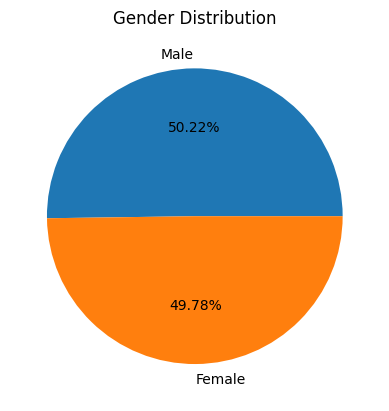

In [40]:
df['gender'].value_counts().plot(
    kind='pie', autopct='%1.2f%%'
)
plt.title('Gender Distribution')
plt.ylabel('')
plt.show()



*   Output explanation: Each slice represents a gender category, and the percentage labels show its share of all patient records.
*   Insight: Male patients account for 50.22% and female patients account for 49.78%, indicating an almost equal gender distribution.

### 7. Correlation Heatmap – Numerical Variables

A correlation heatmap displays the strength and direction of relationships between numerical variables using colors and correlation values.
*   Goal: To identify strong, moderate, and weak correlations among multiple numerical variables.
*   Categories used: age, bmi, doctor_experience_years, consultation_fee, satisfaction_score, medicine_cost, lab_test_cost, and total_bill.


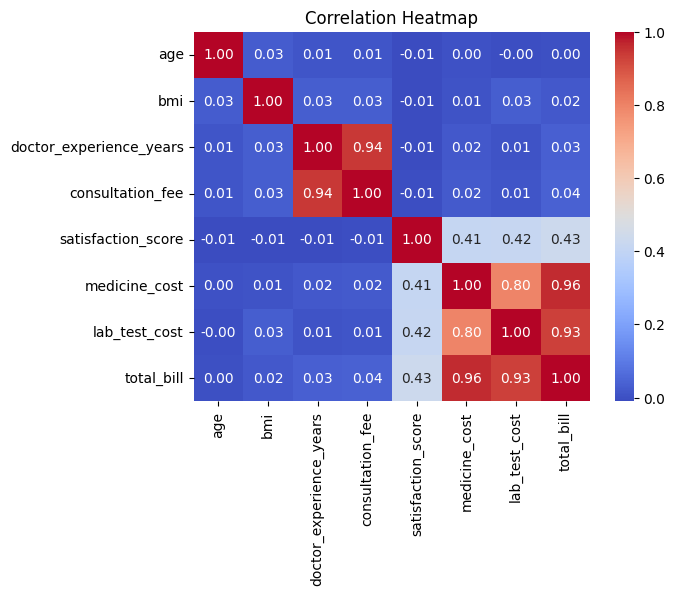

In [41]:
corr = df.select_dtypes(include='number').corr()

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.show()



*   Output explanation: Each cell displays a correlation coefficient between two numerical variables, where values closer to +1 or −1 indicate stronger linear relationships and values near zero indicate weaker ones.
*   Insight: Medicine cost and total bill have a correlation of +0.963, doctor experience and consultation fee have +0.942, and lab test cost and total bill have +0.929.

### 8. Bar Chart – Department-wise Patient Count

A bar chart compares the number of patients across different hospital departments.


*   Goal: Identify which department has the highest and lowest number of patients.
*   Categories used: department – Hospital department, Count of patients




In [42]:
department_count = df['department'].value_counts().reset_index()
department_count.columns = ['Department', 'Patient_Count']

fig = px.bar(
    department_count,
    x='Department',
    y='Patient_Count',
    title='Department-wise Patient Count',
    text='Patient_Count'
)

fig.show()



*   Output explanation: Each bar represents a hospital department. Taller bars indicate more patients. Shorter bars indicate fewer patients.
*   Insight: Cardiology department has the highest patient count and the department with the lowest patient count is Orthopedics.

### 9. Scatter Plot – Doctor Experience vs Consultation Fee

A scatter plot shows the relationship between doctors’ years of experience and their consultation fees.


*   Goal: Determine whether consultation fees tend to increase with doctor experience.
*   Categories used: doctor_experience_years – X-axis, consultation_fee – Y-axis



In [43]:
fig = px.scatter(
    df,
    x='doctor_experience_years',
    y='consultation_fee',
    title='Doctor Experience vs Consultation Fee',
    labels={
        'doctor_experience_years': 'Doctor Experience (Years)',
        'consultation_fee': 'Consultation Fee'
    }
)

fig.show()



*   Output explanation: Each point represents a patient record associated with a doctor's experience and consultation fee. An upward pattern indicates that higher experience is associated with higher consultation fees. A scattered pattern indicates a weaker relationship.
*   Insight: The correlation is approximately +0.942, indicating a very strong positive relationship between doctor experience and consultation fee. In this dataset, more experienced doctors tend to have higher consultation fees.


### 10. Violin Plot – Satisfaction Score by Appointment Status

Shows the distribution and density of satisfaction scores for each appointment status.
*   Goal: Compare patient satisfaction patterns across appointment statuses.
*   Categories used:
    - appointment_status
    - satisfaction_score

In [44]:
fig = px.violin(
    df,
    x='appointment_status',
    y='satisfaction_score',
    box=True,
    title='Patient Satisfaction by Appointment Status',
    color='appointment_status',
    color_discrete_sequence=['green', 'orange', 'red']
)

fig.show()

*   Output explanation: Satisfaction scores are concentrated around 9.6–10 for Completed and Cancelled appointments, while No Show scores have a wider spread, extending down to around 9.4 within the box.
*   Insight: Patient satisfaction is generally high, with no-show appointments showing greater variation in scores.